# Pratinjau Denah Lantai 1
Notebook ini memuat data ruangan + konfigurasi Lt. 1, memvalidasi geometri (overlap, dinding bersama, keterjangkauan) lalu menggambar denahnya. Jalankan semua sel (`Run All`) dan bandingkan dengan foto denah asli.

Kebutuhan: `pip install geopandas shapely matplotlib pandas`

In [1]:
%pip install geopandas shapely matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [20]:
import io, os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import box, Point
from shapely.ops import unary_union

# --- Data ruangan (identik dengan csv/lantai1.csv) ---
CSV_TEXT = """floor,room_id,name,type,xmin,ymin,xmax,ymax
1,01003,Tangga Barat Lt 1,Stairs,0,49.5,3,60
1,113003,113C,Lab,3,58,5.5,60
1,113002,113B,Lab,3,55,5.5,58
1,113001,Microscopes (113A),Lab,3,49.5,5.5,55
1,112,Laboratorium Mikrobiologi (112),Lab,5.5,49.5,24.5,60
1,111,Laboratorium Parasitologi (111),Lab,24.5,49.5,34.5,60
1,001001,Toilet Wanita Lt 1,Toilet,36.5,54.5,40,60
1,001002,Toilet Pria Lt 1,Toilet,36.5,49.5,40,54.5
1,102,Musholla Wanita (102),PrayerRoom,40,56,45.5,60
1,101,LOT (101),Lab,40,49.5,45.5,56
1,103,Ruang Server (103),ServerRoom,45.5,57.7,49.5,60
1,01001,Lift Barat Lt 1,Lift,45.5,53.3,49.5,57.7
1,12,Bank,ATMRoom,45.5,49.5,49.5,53.3
1,114,Laboratorium Biokimia (114),Lab,0,40,15,46.5
1,115,Laboratorium Patologi Klinik (115),Lab,15,40,29,46.5
1,115001,Lab Penelitian (115A),Lab,29,40,36.5,46.5
1,116,Health Care Room (116),Clinic,36.5,40,40,44.5
1,01002,Lift Timur Lt 1,Lift,53.5,50,57.5,60
1,01004,Tangga Utara Lt 1,Stairs,57.5,50,60.5,60
1,104,Workshop & Business Unit (104),Lab,60.5,50,70,60
1,105,CBz Hot Kitchen Lab (105),Lab,70,50,78.5,60
1,106,Restaurant & Bar (106),Lab,60.5,40,70,50
1,108,CBz Pastry Kitchen Lab (108),Lab,70,40,78.5,47
1,107,CBz Kitchen Studio Lab (107),Lab,78.5,40,88.5,60
1,107001,Laboratorium Support (107A),Lab,78.5,40,80.5,44.5
1,109,CBz Kitchen Studio Lab (109),Lab,88.5,40,99.5,50
1,110,CBz Beverages Lab (110),Lab,88.5,50,96.5,60
1,01005,Tangga Timur Lt 1,Stairs,96.5,50,99.5,60
1,10,UC Main Building Lobby,Outdoor,45.5,60,57.5,64
1,11,UC Plaza,Outdoor,38,0,62,40
1,01006,Tangga Selatan Lt 1,Stairs,62,0,71,3
"""
rooms = pd.read_csv(io.StringIO(CSV_TEXT), dtype={"floor": str, "room_id": str})

# --- Konfigurasi (identik dengan floors/lantai1.py) ---
OUTLINE = [
    (0.0, 40.0, 99.5, 60.0),    # badan gedung
    (38.0, 0.0, 62.0, 40.0),    # UC Plaza
]
VOIDS = []
START = (50.0, 45.0)
PART_OF = {
    "10": (52.25, 59.0),
    "11": (50.0, 38.0),
}
LINKS = {
    "01003": {"up": "2", "down": None, "cost": 10},
    "01004": {"up": "2", "down": None, "cost": 10},
    "01005": {"up": "2", "down": None, "cost": 10},
    "01006": {"up": "2", "down": None, "cost": 10},
    "01001": {"up": "2", "down": None, "cost": 6},
    "01002": {"up": "2", "down": None, "cost": 6},
}

rooms["geometry"] = [box(r.xmin, r.ymin, r.xmax, r.ymax) for r in rooms.itertuples()]
gdf = gpd.GeoDataFrame(rooms, geometry="geometry")
print(f"{len(gdf)} ruangan dimuat")
gdf[["room_id", "name", "type", "xmin", "ymin", "xmax", "ymax"]]


31 ruangan dimuat


,room_id,name,type,xmin,ymin,xmax,ymax
0,01003,Tangga Barat Lt 1,Stairs,0.0,49.5,3.0,60.0
1,113003,113C,Lab,3.0,58.0,5.5,60.0
2,113002,113B,Lab,3.0,55.0,5.5,58.0
3,113001,Microscopes (113A),Lab,3.0,49.5,5.5,55.0
4,112,Laboratorium Mikrobiologi (112),Lab,5.5,49.5,24.5,60.0
5,111,Laboratorium Parasitologi (111),Lab,24.5,49.5,34.5,60.0
6,001001,Toilet Wanita Lt 1,Toilet,36.5,54.5,40.0,60.0
7,001002,Toilet Pria Lt 1,Toilet,36.5,49.5,40.0,54.5
8,102,Musholla Wanita (102),PrayerRoom,40.0,56.0,45.5,60.0
9,101,LOT (101),Lab,40.0,49.5,45.5,56.0


## Validasi geometri & walkable area

In [21]:
# ===== Validasi geometri =====
overlaps, shared = [], 0
for i in range(len(gdf)):
    for j in range(i + 1, len(gdf)):
        a, b = gdf.iloc[i], gdf.iloc[j]
        inter = a.geometry.intersection(b.geometry)
        if inter.area > 1e-6:
            overlaps.append((a.room_id, b.room_id, round(inter.area, 3)))
        elif inter.length > 1e-6:
            shared += 1
print("ID duplikat          :", gdf.room_id[gdf.room_id.duplicated()].tolist() or "tidak ada")
print("Overlap antar ruangan :", overlaps or "tidak ada")
print("Pasangan ruangan dengan dinding bersama:", shared)

outline = unary_union([box(*b) for b in OUTLINE])
voids = unary_union([box(*b) for b in VOIDS]) if VOIDS else box(0, 0, 0, 0)
# Lobby (10) sengaja berada di utara OUTLINE (area gedung utama), jadi dikecualikan dari cek ini
outside = [r.room_id for r in gdf.itertuples() if not outline.buffer(1e-6).contains(r.geometry)]
print("Ruangan di luar OUTLINE:", outside or "tidak ada")

# ===== Walkable area (OUTLINE - ruangan - VOIDS) =====
walkable = outline.difference(unary_union(list(gdf.geometry))).difference(voids)
parts = list(walkable.geoms) if walkable.geom_type == "MultiPolygon" else [walkable]
main = next(p for p in parts if p.buffer(1e-6).contains(Point(START)))
print(f"Walkable total {walkable.area:.1f} m2 | komponen dari START {main.area:.1f} m2 | jumlah komponen {len(parts)}")

unreach = [f"{r.room_id} {r.name}" for r in gdf.itertuples() if not r.geometry.buffer(0.05).intersects(main)]
print("Ruangan yang TIDAK menyentuh area walkable:", unreach or "tidak ada")
for k, p in PART_OF.items():
    print(f"PART_OF {k} walkable?", main.buffer(1e-6).contains(Point(p)))
print("LINKS dengan room_id tidak ada:", [k for k in LINKS if k not in set(gdf.room_id)] or "tidak ada")


ID duplikat          : tidak ada
Overlap antar ruangan : [('107', '107001', 9.0)]
Pasangan ruangan dengan dinding bersama: 41
Ruangan di luar OUTLINE: ['10', '01006']
Walkable total 413.8 m2 | komponen dari START 388.2 m2 | jumlah komponen 2
Ruangan yang TIDAK menyentuh area walkable: ['113003 113C', '113002 113B', '102 Musholla Wanita (102)', '105 CBz Hot Kitchen Lab (105)', '108 CBz Pastry Kitchen Lab (108)', '107 CBz Kitchen Studio Lab (107)', '107001 Laboratorium Support (107A)', '109 CBz Kitchen Studio Lab (109)', '110 CBz Beverages Lab (110)', '01005 Tangga Timur Lt 1', '01006 Tangga Selatan Lt 1']
PART_OF 10 walkable? True
PART_OF 11 walkable? False
LINKS dengan room_id tidak ada: tidak ada


## Gambar denah

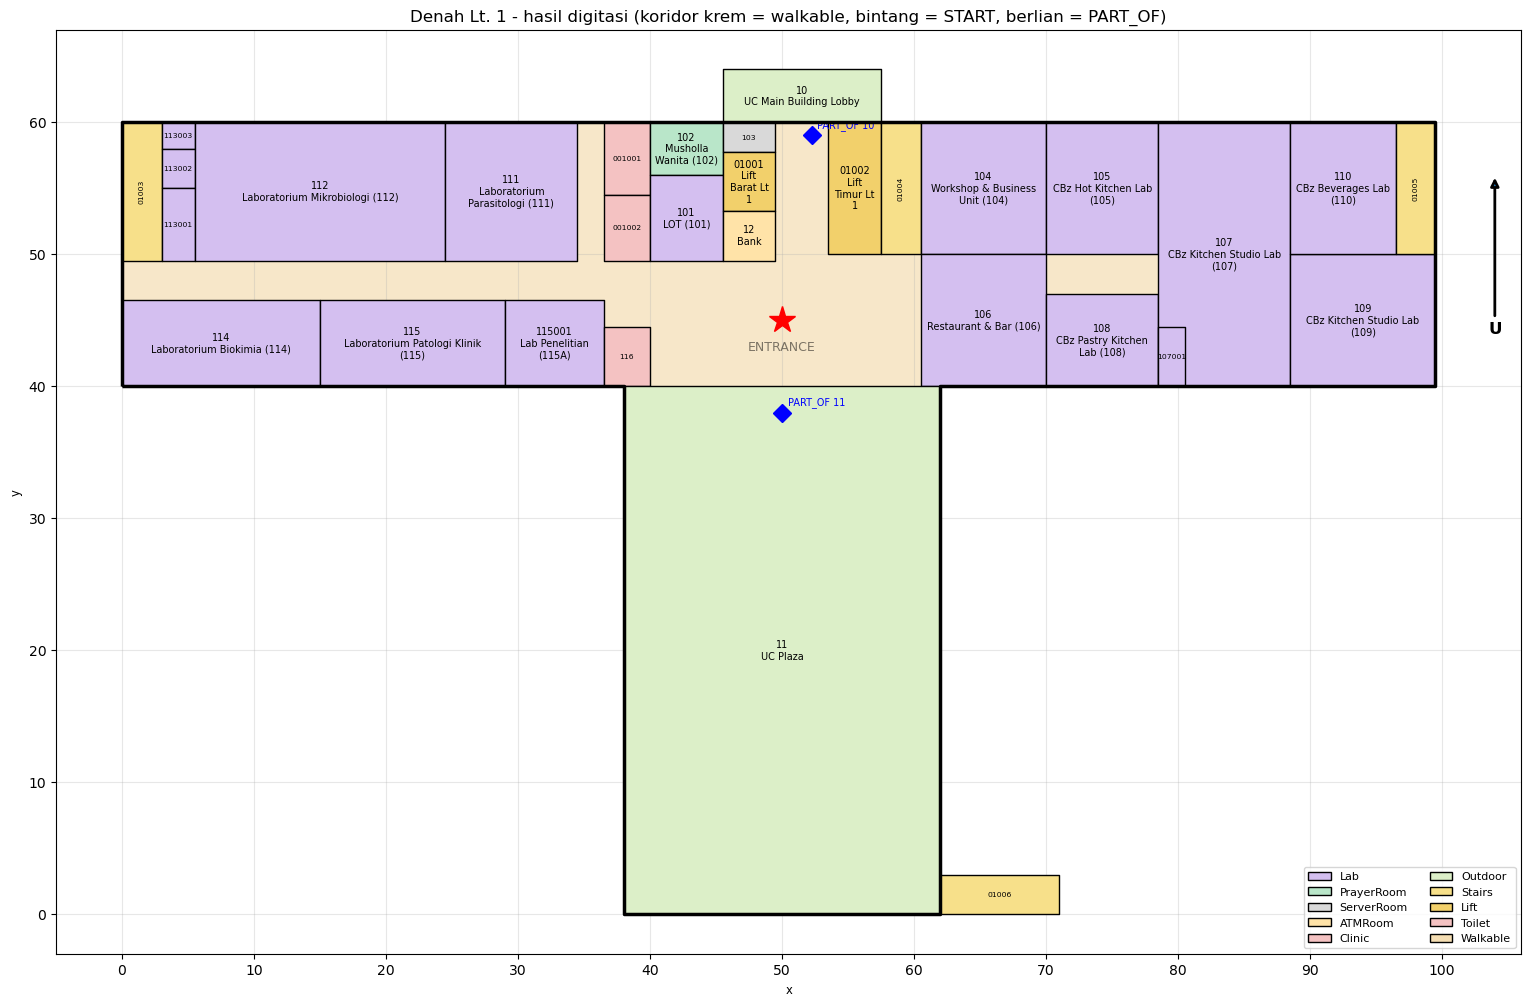

In [22]:
import textwrap
COLORS = {
    "Lab": "#d4bff0", "PrayerRoom": "#b9e6c9", "ServerRoom": "#d9d9d9", "ATMRoom": "#ffe3a8",
    "Clinic": "#f4c2c2", "Outdoor": "#dcefc8", "Stairs": "#f7e08a", "Lift": "#f2d06b", "Toilet": "#f4c2c2",
}
fig, ax = plt.subplots(figsize=(20, 12))
gpd.GeoSeries([walkable]).plot(ax=ax, color="#f5deb3", alpha=0.7, zorder=1)
if VOIDS:
    gpd.GeoSeries([voids]).plot(ax=ax, facecolor="#bbbbbb", edgecolor="#666666", hatch="////", zorder=2)
gdf.plot(ax=ax, color=gdf["type"].map(COLORS), edgecolor="black", linewidth=1.0, zorder=3)
gpd.GeoSeries([outline]).boundary.plot(ax=ax, color="black", linewidth=2.5, zorder=4)

for r in gdf.itertuples():
    cx, cy = r.geometry.centroid.x, r.geometry.centroid.y
    w, h = r.xmax - r.xmin, r.ymax - r.ymin
    small = min(w, h) < 3.6
    label = r.room_id if small else r.room_id + "\n" + textwrap.fill(r.name, max(6, int(w * 2.4)))
    ax.text(cx, cy, label, ha="center", va="center", fontsize=5.5 if small else 7,
            rotation=90 if h > 2.5 * w else 0, zorder=6)

ax.plot(*START, marker="*", color="red", markersize=20, zorder=7, label="START")
for k, p in PART_OF.items():
    ax.plot(*p, marker="D", color="blue", markersize=9, zorder=7)
    ax.annotate(f"PART_OF {k}", p, xytext=(4, 6), textcoords="offset points", fontsize=7, color="blue")

ax.text(50, 43, "ENTRANCE", ha="center", va="center", fontsize=9, alpha=0.5, zorder=5)
ax.annotate("U", xy=(104, 56), xytext=(104, 44), ha="center", fontsize=12, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", lw=2))
ax.set_xlim(-5, 106); ax.set_ylim(-3, 67)
ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 61, 10))
ax.set_title("Denah Lt. 1 - hasil digitasi (koridor krem = walkable, bintang = START, berlian = PART_OF)")
legend = [Patch(facecolor=c, edgecolor="black", label=t) for t, c in COLORS.items()]
legend.append(Patch(facecolor="#f5deb3", edgecolor="black", label="Walkable"))
ax.legend(handles=legend, loc="lower right", fontsize=8, ncol=2)
fig.savefig("lantai1_preview.png", dpi=130, bbox_inches="tight")
plt.show()


In [23]:
rooms.to_csv("csv/lantai1.csv", index=False)

In [26]:
rooms.drop(columns=['geometry']).to_csv("csv/lantai1.csv", index=False)

## Overlay ke foto denah asli (opsional)

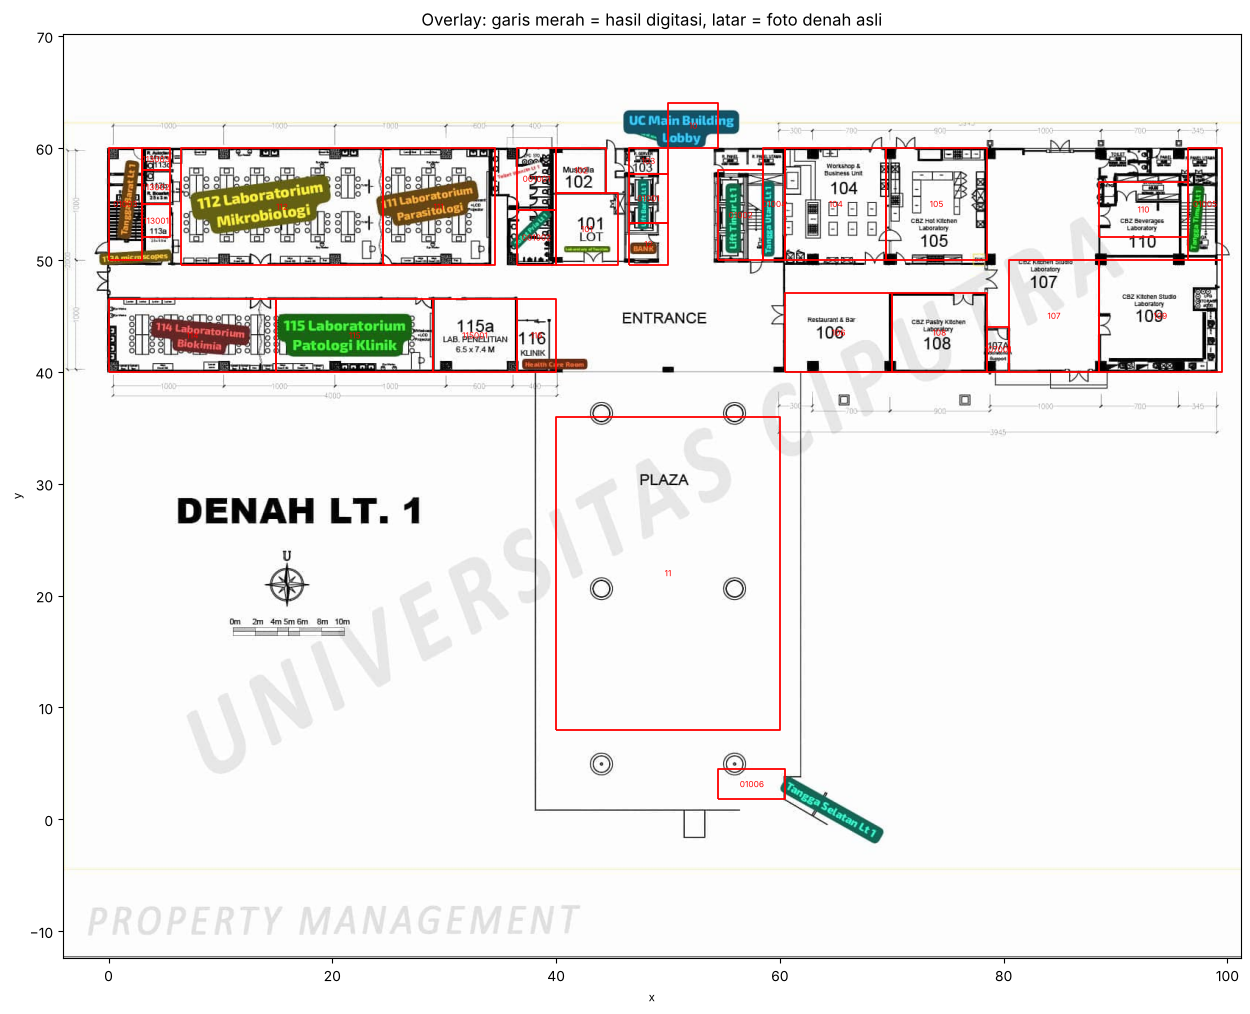

In [5]:
# Opsional: tempel kerangka hasil digitasi di atas foto denah asli untuk cek kesesuaian.
# Simpan foto denah Lt. 1 sebagai "denah_lt1.jpg" di folder yang sama dengan notebook ini.
IMAGE_PATH = "denah_lt1.jpg"
if os.path.exists(IMAGE_PATH):
    import matplotlib.image as mpimg
    img = mpimg.imread(IMAGE_PATH)
    H, W = img.shape[0], img.shape[1]
    # kalibrasi untuk foto 1600x1280 px: x=0 m di px 62, 15.2 px/m; y=60 m di px 158, 15.5 px/m
    X0, Y0, SX, SY = 62, 158, 15.2, 15.5
    extent = [-X0 / SX, (W - X0) / SX, 60 - (H - Y0) / SY, 60 + Y0 / SY]
    fig, ax = plt.subplots(figsize=(20, 12))
    ax.imshow(img, extent=extent, zorder=0)
    gdf.boundary.plot(ax=ax, color="red", linewidth=1.3, zorder=3)
    for r in gdf.itertuples():
        ax.text(r.geometry.centroid.x, r.geometry.centroid.y, r.room_id, color="red",
                fontsize=6, ha="center", va="center", zorder=4)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title("Overlay: garis merah = hasil digitasi, latar = foto denah asli")
    plt.show()
else:
    print(f"{IMAGE_PATH} tidak ditemukan - lewati overlay (opsional).")
